<a href="https://colab.research.google.com/github/Raditya-Z/MachineLearning_244107020144/blob/main/JS-09/JS_09_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🥚 Tugas 1

1. Memuat dataset dan mengecek data

In [2]:
# Langkah 1: Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Langkah 2: Membaca dataset

df = pd.read_csv("voice.csv")

# Langkah 3: Melihat data
print("Lima data pertama:")
display(df.head())

print("Ukuran dataset:", df.shape)
print("\nInformasi dataset:")
df.info()

print("\nJumlah data berdasarkan label:")
print(df["label"].value_counts())

Lima data pertama:


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Ukuran dataset: (3168, 21)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-nul

2. Membagi data dan membuat model kNN

Sebelum melatih model, data dibagi menjadi 80% data latih dan 20% data uji. Fitur juga distandardisasi agar perbedaan skala antarvariabel tidak memengaruhi perhitungan jarak kNN secara berlebihan

In [3]:
# Langkah 4: Memisahkan fitur dan label
X = df.drop(columns=["label"])
y = df["label"]

# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))
print("Jumlah fitur:", X.shape[1])

Jumlah data training: 2534
Jumlah data testing: 634
Jumlah fitur: 20


3. Mencari fitur yang paling optimal dan nilai K terbaik

Menggunakan SelectKBest untuk memilih sejumlah fitur terbaik berdasarkan uji statistik ANOVA (f_classif). Selanjutnya, GridSearchCV mencoba kombinasi jumlah fitur dan nilai \(K\) dengan validasi silang 5 lipatan.

Dengan cara ini, pemilihan fitur dan nilai \(K\) dilakukan menggunakan data latih, sedangkan data uji disimpan untuk evaluasi akhir.

In [4]:
# Langkah 5: Membuat pipeline kNN
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_classif)),
    ("knn", KNeighborsClassifier())
])

# Mencoba jumlah fitur dan nilai K yang berbeda
parameter = {
    "selector__k": list(range(1, X.shape[1] + 1)),
    "knn__n_neighbors": list(range(1, 22))
}

# Pencarian kombinasi terbaik dengan validasi silang
grid = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Menampilkan hasil terbaik
print("Parameter terbaik:", grid.best_params_)
print("Akurasi validasi terbaik:", round(grid.best_score_, 4))

# Model terbaik
best_model = grid.best_estimator_

# Mengambil nama fitur yang terpilih
selector = best_model.named_steps["selector"]
fitur_terpilih = X.columns[selector.get_support()]

print("\nFitur terbaik yang terpilih:")
for fitur in fitur_terpilih:
    print("-", fitur)

# Evaluasi akhir pada data testing
y_pred = best_model.predict(X_test)

print("\nAkurasi data testing:",
      round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred))

Parameter terbaik: {'knn__n_neighbors': 6, 'selector__k': 9}
Akurasi validasi terbaik: 0.9795

Fitur terbaik yang terpilih:
- meanfreq
- sd
- median
- Q25
- IQR
- sp.ent
- sfm
- centroid
- meanfun

Akurasi data testing: 0.989

Confusion Matrix:
[[314   3]
 [  4 313]]

Laporan Klasifikasi:
              precision    recall  f1-score   support

      female       0.99      0.99      0.99       317
        male       0.99      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



4. Grafik analisis jumlah fitur

Grafik ini memperlihatkan hubungan jumlah fitur yang digunakan dengan skor rata-rata validasi silang. Setiap jumlah fitur dibandingkan berdasarkan skor terbaik dari nilai \(K\) yang diuji.

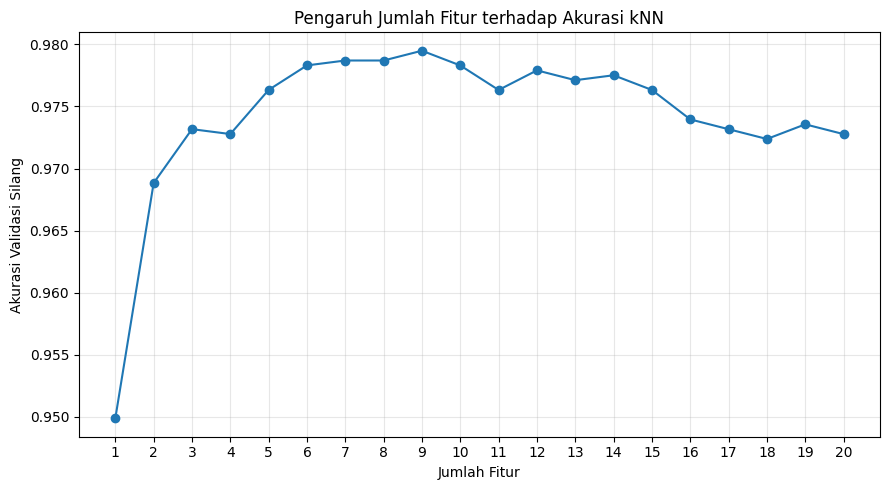

In [5]:
# Langkah 6: Grafik jumlah fitur vs akurasi validasi
hasil = pd.DataFrame(grid.cv_results_)

akurasi_fitur = hasil.groupby(
    hasil["param_selector__k"].astype(int)
)["mean_test_score"].max()

plt.figure(figsize=(9, 5))
plt.plot(
    akurasi_fitur.index,
    akurasi_fitur.values,
    marker="o"
)

plt.xlabel("Jumlah Fitur")
plt.ylabel("Akurasi Validasi Silang")
plt.title("Pengaruh Jumlah Fitur terhadap Akurasi kNN")
plt.xticks(range(1, X.shape[1] + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

5. Grafik analisis nilai K

Setelah jumlah fitur terbaik diketahui, grafik berikut menunjukkan pengaruh nilai \(K\) terhadap akurasi validasi silang untuk jumlah fitur tersebut.

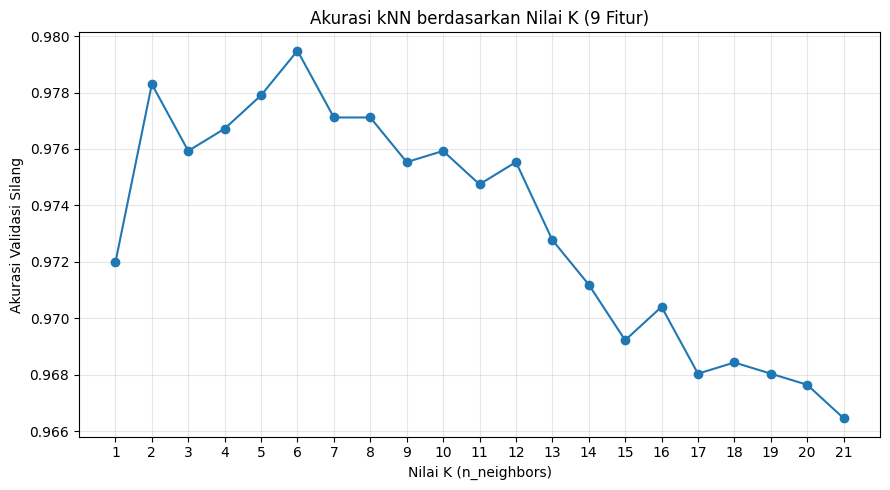

Jumlah fitur terbaik: 9
Nilai K terbaik: 6
Akurasi validasi terbaik: 0.9795


In [6]:
# Langkah 7: Grafik nilai K terbaik
jumlah_fitur_terbaik = grid.best_params_["selector__k"]

hasil_k = hasil[
    hasil["param_selector__k"].astype(int)
    == jumlah_fitur_terbaik
].copy()

hasil_k["nilai_k"] = hasil_k["param_knn__n_neighbors"].astype(int)
hasil_k = hasil_k.sort_values("nilai_k")

plt.figure(figsize=(9, 5))
plt.plot(
    hasil_k["nilai_k"],
    hasil_k["mean_test_score"],
    marker="o"
)

plt.xlabel("Nilai K (n_neighbors)")
plt.ylabel("Akurasi Validasi Silang")
plt.title(
    f"Akurasi kNN berdasarkan Nilai K "
    f"({jumlah_fitur_terbaik} Fitur)"
)
plt.xticks(range(1, 22))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Jumlah fitur terbaik:", jumlah_fitur_terbaik)
print("Nilai K terbaik:", grid.best_params_["knn__n_neighbors"])
print("Akurasi validasi terbaik:", round(grid.best_score_, 4))

**Analisis**
> Berdasarkan hasil percobaan menggunakan algoritma k-Nearest Neighbors (kNN) pada dataset voice.csv, diperoleh akurasi validasi sebesar 97,95% dan akurasi data testing sebesar 98,90%. Kombinasi terbaik menggunakan 9 fitur, yaitu meanfreq, sd, median, Q25, IQR, sp.ent, sfm, centroid, dan meanfun, dengan nilai \(K=6\). Grafik menunjukkan bahwa penggunaan 9 fitur dan nilai \(K=6\) menghasilkan akurasi validasi tertinggi dibandingkan kombinasi lain yang diuji. Dari 634 data testing, sebanyak 627 data berhasil diklasifikasikan dengan benar, sedangkan 7 data lainnya salah diklasifikasikan. Hal ini menunjukkan bahwa model kNN mampu membedakan suara laki-laki dan perempuan dengan baik.

**Kesimpulan**
> Algoritma kNN dapat digunakan untuk mengklasifikasikan jenis suara laki-laki dan perempuan dengan tingkat akurasi yang tinggi. Berdasarkan percobaan, kombinasi terbaik adalah 9 fitur dengan nilai \(K=6\), yang menghasilkan akurasi validasi 97,95% dan akurasi testing 98,90%. Dengan demikian, pemilihan fitur dan nilai \(K\) yang tepat berpengaruh terhadap kinerja model, meskipun masih terdapat sedikit kesalahan dalam proses klasifikasi.